# LRB-D with the one-ancilla layout's five-moment round, qubit code: SI1000 and SD6

This notebook plots the two production LRB-D runs of profile `folded_qubit_prod5b`: the paper's one-ancilla layout and its twelve check CNOTs in the order that packs them into five gate moments (the five-moment round). The published runs use the same gates in seven gate moments (the seven-moment round). The user chose the five-moment round for the paper on 2026-11-19.

**Round.** Same layout, ancillas, CNOT powers, H/H^-1 and readouts as the seven-moment round. Only the order of the gates on each wire changes, so the ASAP scheduler packs the round into 5 gate moments instead of 7 (plus one reset and one readout moment):

- m1: a1 reads q1; H on a3, a4
- m2: a1 reads q0; a3 reads q2; a4 reads q1
- m3: a1 reads q3; a2 reads q2; a3 reads q0; a4 reads q4
- m4: a2 reads q4; a3 reads q1; a4 reads q3
- m5: a2 reads q1; H^-1 on a3, a4

Of all 31,104 correct gate orders of this round (qutrit code), this one has the lowest leading-order undetected logical error per round under both SI1000 and SD6, and no single fault is undetected (`comparisons/two-ancilla-checks/hw-layouts/one-ancilla/`).

**Pairing.** Each run is a paired copy of a published qubit one-ancilla run (`scripts/make_round_variant.py`): the same 30 Clifford sequences (decoded from the published run's files, which they reproduce byte for byte), the same depths, p grid, shots and check policies, and byte-identical RB circuits. Only the check round differs. Same noise, mirror inverse, fit settings and threshold estimator as the other sdim 1.4.0 runs.


### 0. Environment check

The kernel should be the repo venv (`.venv-sdim140`), which pins sdim 1.4.0.

In [1]:
from importlib.metadata import version
version("sdim")

'1.4.0'

### 1. Shared imports and configuration

Same fit, threshold, GIF and paper settings as the earlier DEM notebooks, except the axis is the two-qudit gate error $p$ (`p_axis_scale=1.0`).

In [2]:
from pathlib import Path
import sys
import importlib

import pandas as pd
from IPython.display import Image, display


def find_repo_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "src" / "lrb" / "lrb_plotting.py").exists():
            return candidate
    raise FileNotFoundError("Could not locate repository root containing src/lrb/lrb_plotting.py")


REPO_ROOT = find_repo_root(Path.cwd())
SRC_PATH = REPO_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

import lrb.lrb_plotting as _lrb_plotting
import lrb.lrb_gif_plotting as _lrb_gif_plotting

# Ensure notebook uses latest local edits to plotting/GIF modules.
importlib.reload(_lrb_plotting)
importlib.reload(_lrb_gif_plotting)

from lrb.lrb_plotting import (
    LRBPlotFitConfig,
    LRBResultsPlotter,
    LRBThresholdConfig,
    LRBPaperPlotConfig,
)
from lrb.lrb_gif_plotting import LRBGifAnimator, LRBGifRenderConfig


def resolve_working_folder(
    code_name: str,
    lrb_root=None,
) -> str:
    root = Path(lrb_root) if lrb_root is not None else REPO_ROOT / "LRB-experiment-data-slurm"
    code_marker = root / f"working-folder-{code_name}.txt"
    legacy_marker = root / "working-folder.txt"

    def marker_path(marker: Path):
        if not marker.exists():
            return None
        run_name = marker.read_text(encoding="utf-8").strip()
        if not run_name:
            return None
        run_path = root / run_name
        if not run_path.exists():
            return None
        return str(run_path) + "/"

    for marker in (code_marker, legacy_marker):
        maybe_path = marker_path(marker)
        if maybe_path is not None:
            return maybe_path

    candidates = sorted(
        root.glob(f"Run-*-{code_name}*"),
        key=lambda p: p.stat().st_mtime,
        reverse=True,
    )
    if candidates:
        return str(candidates[0]) + "/"

    raise FileNotFoundError(
        f"No run folder found for code '{code_name}' under {root.resolve()}"
    )


fit_config = LRBPlotFitConfig(
    a_fixed=0.0,
    y_ceiling=1.0,
    min_fit_points_lrb=2,
    min_fit_points_rb=3,
    f_min=1e-8,
    f_max=1.0000000,
    rb_a_fixed=0.0,
    # SI1000 and SD6 are parameterized by the two-qudit gate depolarizing
    # probability p (Gidney et al. 2021); plot against it directly.
    p_axis_scale=1.0,
    p_axis_label="Two-qudit gate error rate $p$",
    p_axis_symbol="p",
    p_axis_column=None,
)

threshold_config = LRBThresholdConfig(
    tol=5e-4,
    require_consecutive=2,
    ignore_first_n=3,
    err_floor=2e-3,
    tail_min_prefix=6,
    tail_drop_tol_abs=0.01,
    tail_drop_tol_rel=0.25,
    p_min=None,
    p_max=None,
    min_lrb_n_points_keep=0,
    min_rb_n_points_keep=0,
    zoom_half_window_points=4,
    zoom_pad_frac=0.25,
    min_zoom_span=0.01,
    p_window_before_points=8,
    p_window_after_points=5,
    min_points_in_view=6,
    view_pad_frac=0.15,
    bootstrap_reps_error=500,
    bootstrap_reps_threshold=1000,
    bootstrap_ci_level=0.68,
    bootstrap_use_sem=True,
    bootstrap_seed=12345,
    paper_mode=True,
    paper_cols=2,
    paper_panel_width_in=3.2,
    paper_panel_height_in=2.5,
)

# Shared check ranges for all multi-check plotting/table methods.
const_check_min = 0
const_check_max = 0
unif_check_min = 1
unif_check_max = 22

# Optional pseudo-threshold fit controls.
pseudo_do_fit = False
pseudo_fit_model = "exp"  # or "poly"
pseudo_fit_degree = 1


gif_render_config = LRBGifRenderConfig(
    fps=10,
    dpi=120,
    hold_frames=1,
    transition_frames=6,
)

paper_plot_config = LRBPaperPlotConfig(
    enabled=True,
    column_layout="double",
    rows_per_page=3,
    pairs_per_row=2,
    num_prob_samples=6,
    # Circuit-level range on the production grid:
    # p = 1e-4, 5e-4, 1e-3, 2e-3, 5e-3, 1e-2.
    prob_sample_indices=(1, 3, 4, 5, 6, 8),
    row_height_in=1.6,
    panel_title_fontsize=7.0,
    axis_label_fontsize=6.6,
    tick_fontsize=6.0,
    legend_fontsize=5.7,
    line_width=0.85,
    marker_size=2.6,
    errorbar_capsize=1.2,
    show_legend_first_row_only=False,
    compact_fit_legend=True,
    legend_on_rejected_panel=True,
)

def show_error_rate_uncertainty_table(table_csv: str, label: str) -> pd.DataFrame:
    frame = pd.read_csv(table_csv)
    coordinate_columns = [
        c for c in ("lrb_lambda", "rb_p", "lambda", "p_raw", "p")
        if c in frame.columns
    ]
    sort_column = "lrb_lambda" if "lrb_lambda" in frame.columns else coordinate_columns[0]
    needed = [
        "check_num",
        *coordinate_columns,
        "lrb_error_rate",
        "lrb_error_rate_ci_low",
        "lrb_error_rate_ci_high",
        "rb_error_rate",
        "rb_error_rate_ci_low",
        "rb_error_rate_ci_high",
    ]
    missing = [c for c in needed if c not in frame.columns]
    if missing:
        raise ValueError(
            f"Missing uncertainty columns in {table_csv}: {missing}. "
            "Re-run the table generation cell."
        )

    view = frame[needed].copy()
    view["lrb_unc_minus"] = view["lrb_error_rate"] - view["lrb_error_rate_ci_low"]
    view["lrb_unc_plus"] = view["lrb_error_rate_ci_high"] - view["lrb_error_rate"]
    view["rb_unc_minus"] = view["rb_error_rate"] - view["rb_error_rate_ci_low"]
    view["rb_unc_plus"] = view["rb_error_rate_ci_high"] - view["rb_error_rate"]
    view = view.sort_values(["check_num", sort_column]).reset_index(drop=True)

    print(f"[{label}] error-rate uncertainty table")
    display(view)
    return view

def show_pseudo_threshold_uncertainty_table(
    summary_csv: str,
    label: str,
    check_min=None,
    check_max=None,
) -> pd.DataFrame:
    frame = pd.read_csv(summary_csv)
    threshold_column = (
        "threshold_lrb_lambda"
        if "threshold_lrb_lambda" in frame.columns
        else "threshold_lambda"
        if "threshold_lambda" in frame.columns
        else "threshold_p"
    )
    threshold_std_column = f"{threshold_column}_std_boot"
    threshold_ci_low_column = f"{threshold_column}_ci_low"
    threshold_ci_high_column = f"{threshold_column}_ci_high"
    needed = ["check_num", threshold_column]
    missing = [c for c in needed if c not in frame.columns]
    if missing:
        raise ValueError(
            f"Missing pseudo-threshold columns in {summary_csv}: {missing}. "
            "Re-run threshold generation first."
        )

    view = frame.copy()
    if check_min is not None:
        view = view[view["check_num"] >= int(check_min)]
    if check_max is not None:
        view = view[view["check_num"] <= int(check_max)]
    view = view[view[threshold_column].notna()].copy()

    keep = ["check_num", threshold_column]
    has_std = threshold_std_column in view.columns
    has_ci = (
        threshold_ci_low_column in view.columns
        and threshold_ci_high_column in view.columns
    )
    if has_std:
        keep.append(threshold_std_column)
    if has_ci:
        keep.extend([threshold_ci_low_column, threshold_ci_high_column])

    table = view[keep].copy()
    if has_ci:
        table["threshold_unc_minus"] = (
            table[threshold_column] - table[threshold_ci_low_column]
        )
        table["threshold_unc_plus"] = (
            table[threshold_ci_high_column] - table[threshold_column]
        )
    elif has_std:
        table["threshold_unc_minus"] = table[threshold_std_column]
        table["threshold_unc_plus"] = table[threshold_std_column]
    else:
        raise ValueError(
            f"No pseudo-threshold uncertainty columns found in {summary_csv}."
        )

    table = table.sort_values(["check_num"]).reset_index(drop=True)
    print(f"[{label}] pseudo-threshold uncertainty table")
    display(table)
    return table

### 2. Run selection and output audit

Runs are named explicitly so the notebook does not depend on the mutable `working-folder-*.txt` pointers. The audit requires every LRB and RB CSV before plotting.

In [3]:
RUNS_ROOT = REPO_ROOT / "LRB-experiment-data-slurm"
RUN_NAMES = {
    "prod5b_qubit_si1000": "Run-2026-11-19-23-39-09-folded_qubit_prod5b-single-ancilla-si1000-sdim140",
    "prod5b_qubit_sd6": "Run-2026-11-19-23-39-27-folded_qubit_prod5b-single-ancilla-sd6-sdim140",
}
EXPECTED_METADATA = {
    "prod5b_qubit_si1000": ("folded_qubit_prod5b", "si1000"),
    "prod5b_qubit_sd6": ("folded_qubit_prod5b", "sd6"),
}


def read_int_list(path: Path) -> list[int]:
    return [int(v) for v in path.read_text().replace(",", " ").split()]


def read_float_list(path: Path) -> list[float]:
    return [float(v) for v in path.read_text().replace(",", " ").split()]


def audit_run(label: str, run_path: Path) -> pd.DataFrame:
    code_name = (run_path / "code_name.txt").read_text().strip()
    noise_model = (run_path / "noise_model.txt").read_text().strip()
    if (code_name, noise_model) != EXPECTED_METADATA[label]:
        raise ValueError(f"{label}: found {(code_name, noise_model)}, expected {EXPECTED_METADATA[label]}")
    probs = read_float_list(run_path / "probs.txt")
    const_checks = read_int_list(run_path / "check_const.txt")
    unif_checks = read_int_list(run_path / "check_unif.txt")
    rows = []
    for idx, prob in enumerate(probs):
        lrb_path = run_path / "results" / "LRB" / str(idx)
        done_path = run_path / "progress" / str(idx) / "done.txt"
        rows.append({
            "run": label,
            "p_index": idx,
            "p": prob,
            "done_flag": done_path.read_text().strip() if done_path.exists() else "missing",
            "const_csvs": len(list((lrb_path / "const_check_data").glob("*.csv"))),
            "expected_const_csvs": len(const_checks),
            "unif_csvs": len(list((lrb_path / "unif_check_data").glob("*.csv"))),
            "expected_unif_csvs": len(unif_checks),
            "rb_csv_present": (run_path / "results" / "RB" / f"{idx}.csv").exists(),
        })
    return pd.DataFrame(rows)


run_paths = {label: RUNS_ROOT / name for label, name in RUN_NAMES.items()}
audit = pd.concat([audit_run(label, path) for label, path in run_paths.items()], ignore_index=True)
summary = audit.groupby("run").agg(
    indices=("p_index", "count"),
    done=("done_flag", lambda s: int((s == "1").sum())),
    lrb_csvs=("const_csvs", "sum"),
    unif_csvs=("unif_csvs", "sum"),
    expected_const=("expected_const_csvs", "sum"),
    expected_unif=("expected_unif_csvs", "sum"),
    rb_csvs=("rb_csv_present", "sum"),
)
display(summary)
incomplete = audit[
    (audit["done_flag"] != "1")
    | (audit["const_csvs"] != audit["expected_const_csvs"])
    | (audit["unif_csvs"] != audit["expected_unif_csvs"])
    | (~audit["rb_csv_present"])
]
if not incomplete.empty:
    raise ValueError("Incomplete runs/indices:\n" + incomplete.to_string())

,indices,done,lrb_csvs,unif_csvs,expected_const,expected_unif,rb_csvs
run,,,,,,,
prod5b_qubit_sd6,15,15,345,330,345,330,15
prod5b_qubit_si1000,15,15,345,330,345,330,15


### 3. Build plotters

One `LRBResultsPlotter` per run. With `p_axis_scale=1.0` and no `rb_comparison_probs.txt`, each plotter pairs LRB at $p$ with physical RB at the same $p$ from `results/RB`.

In [4]:
plotters = {
    label: LRBResultsPlotter(working_folder=str(path) + "/", fit_config=fit_config)
    for label, path in run_paths.items()
}
for label, plotter in plotters.items():
    rb_source, rb_probabilities = plotter._rb_table_source()
    print(f"{label}: {plotter.code_title}")
    print(f"  p grid: {plotter.probabilities}")
    print(f"  RB source: {rb_source}")
    if max(abs(a - b) for a, b in zip(plotter.probabilities, rb_probabilities)) > 0:
        raise ValueError(f"{label}: RB grid is not the LRB p grid.")

prod5b_qubit_si1000: $[[5,1,2]]_2$ one-ancilla, 5-moment round, SI1000
  p grid: [0.0, 0.0001, 0.0002, 0.0005, 0.001, 0.002, 0.005, 0.0075, 0.01, 0.0125, 0.015, 0.02, 0.03, 0.04, 0.05]
  RB source: /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-09-folded_qubit_prod5b-single-ancilla-si1000-sdim140/results/RB
prod5b_qubit_sd6: $[[5,1,2]]_2$ one-ancilla, 5-moment round, SD6
  p grid: [0.0, 0.0001, 0.0002, 0.0005, 0.001, 0.002, 0.005, 0.0075, 0.01, 0.0125, 0.015, 0.02, 0.03, 0.04, 0.05]
  RB source: /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-27-folded_qubit_prod5b-single-ancilla-sd6-sdim140/results/RB


### 4. Constant-check plots

`const_check=0` (the direct terminal-X check) for every run, as in the earlier notebooks.

=== prod5b_qubit_si1000


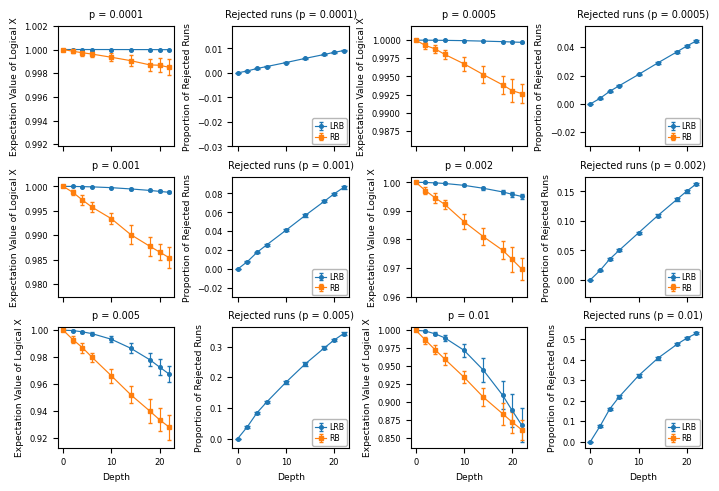

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-09-folded_qubit_prod5b-single-ancilla-si1000-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf
=== prod5b_qubit_sd6


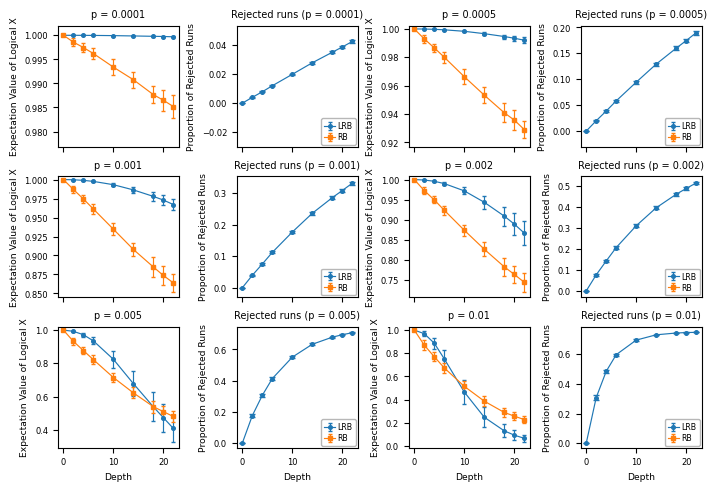

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-27-folded_qubit_prod5b-single-ancilla-sd6-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf


{'prod5b_qubit_si1000': ['/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-09-folded_qubit_prod5b-single-ancilla-si1000-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf'],
 'prod5b_qubit_sd6': ['/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-27-folded_qubit_prod5b-single-ancilla-sd6-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf']}

In [5]:
const_outputs = {}
for label, plotter in plotters.items():
    print(f"=== {label}")
    const_outputs[label] = plotter.plot_all_const_checks(
        show=True,
        check_min=0,
        check_max=0,
        paper_config=paper_plot_config,
    )
const_outputs

### 5. Uniform-check plots

Interval checks `1..4` for every run; raise `unif_plot_max` to `unif_check_max` for all intervals.

=== prod5b_qubit_si1000


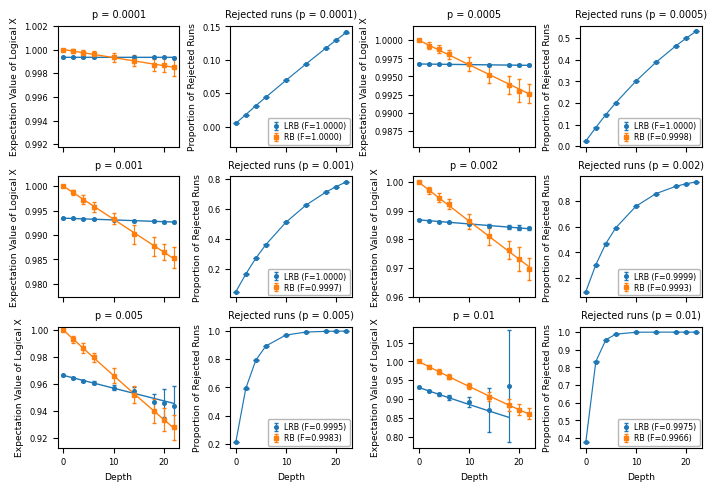

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-09-folded_qubit_prod5b-single-ancilla-si1000-sdim140/results/plots/unif-1-Summary-Graph-Fit.pdf


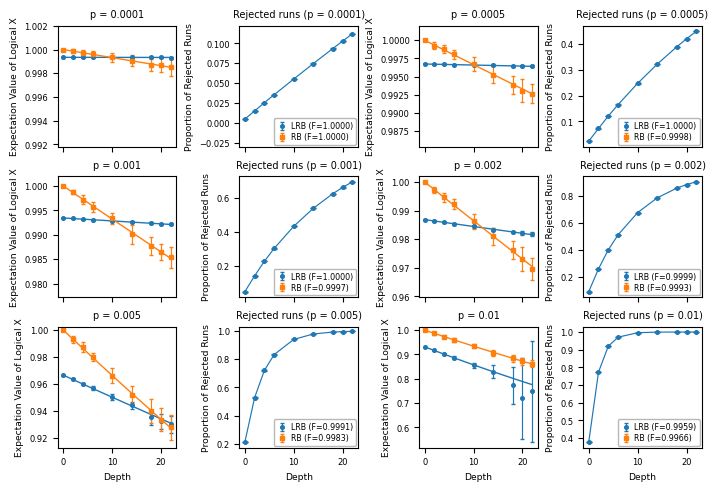

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-09-folded_qubit_prod5b-single-ancilla-si1000-sdim140/results/plots/unif-2-Summary-Graph-Fit.pdf


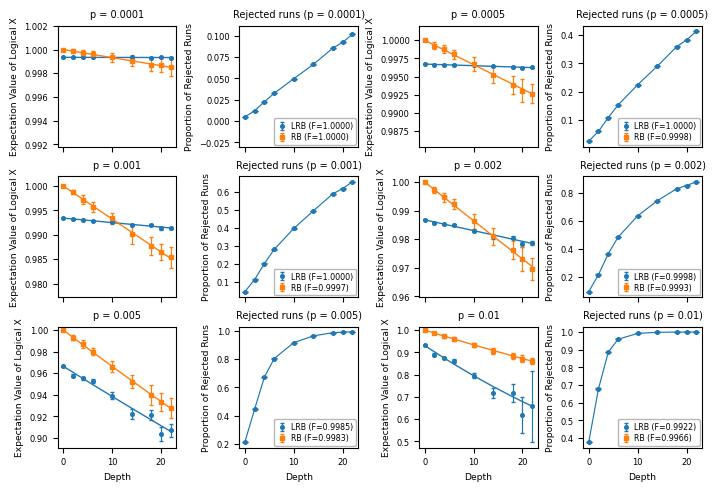

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-09-folded_qubit_prod5b-single-ancilla-si1000-sdim140/results/plots/unif-3-Summary-Graph-Fit.pdf


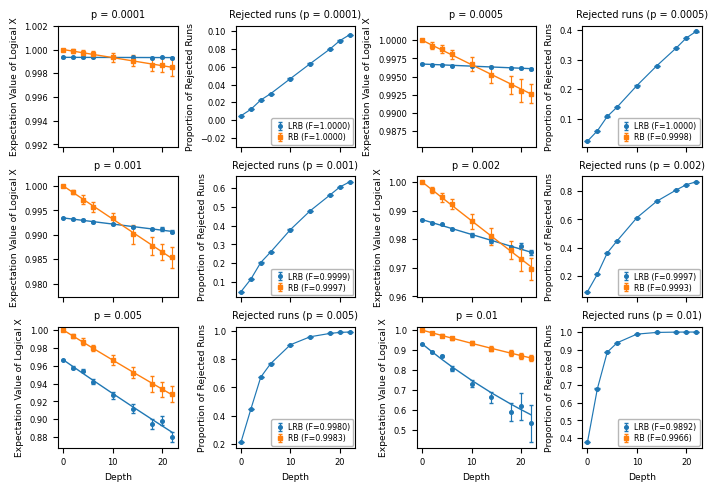

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-09-folded_qubit_prod5b-single-ancilla-si1000-sdim140/results/plots/unif-4-Summary-Graph-Fit.pdf
=== prod5b_qubit_sd6


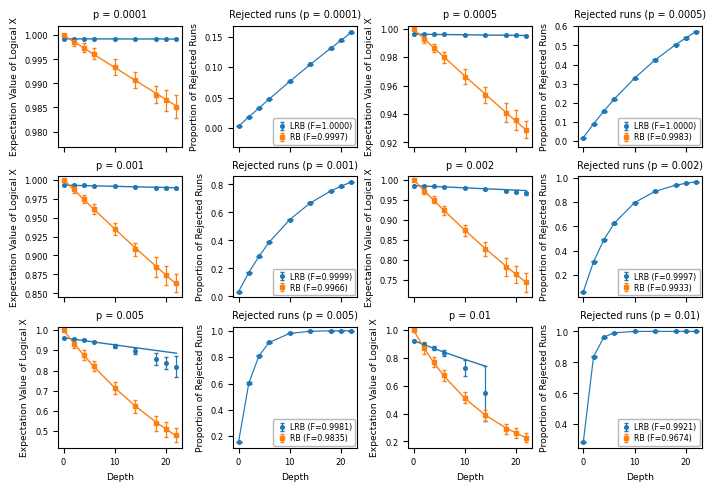

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-27-folded_qubit_prod5b-single-ancilla-sd6-sdim140/results/plots/unif-1-Summary-Graph-Fit.pdf


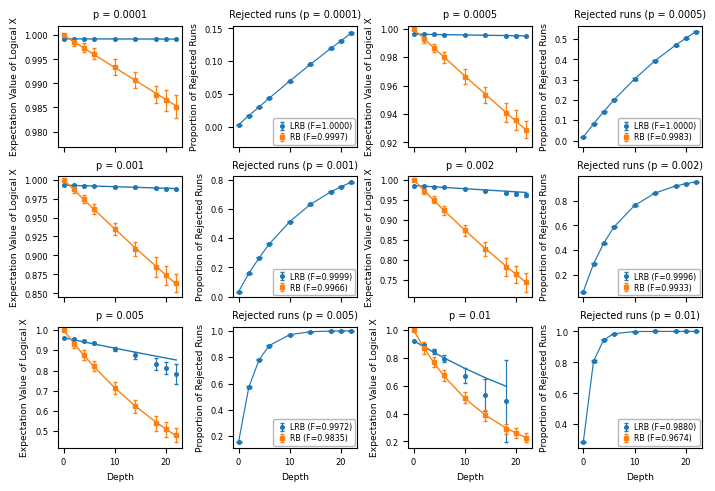

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-27-folded_qubit_prod5b-single-ancilla-sd6-sdim140/results/plots/unif-2-Summary-Graph-Fit.pdf


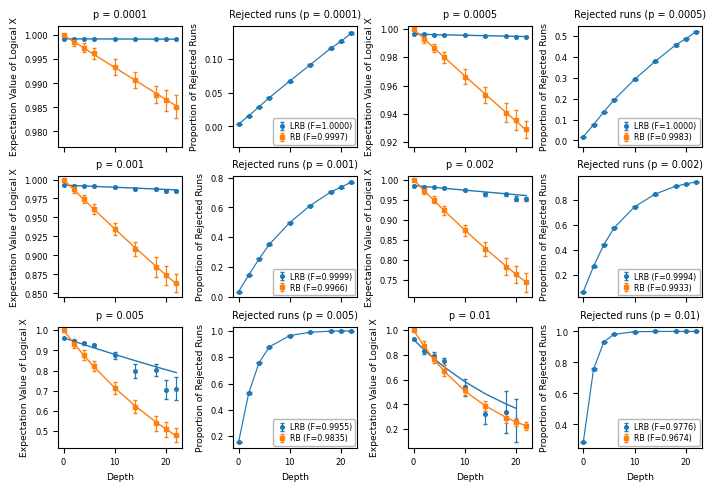

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-27-folded_qubit_prod5b-single-ancilla-sd6-sdim140/results/plots/unif-3-Summary-Graph-Fit.pdf


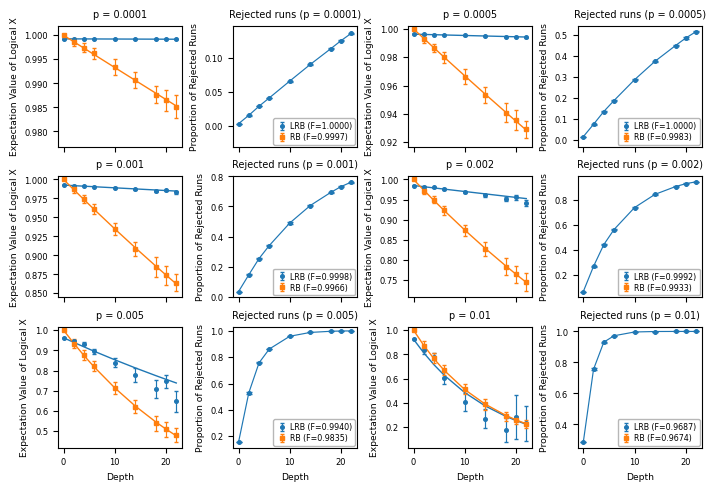

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-27-folded_qubit_prod5b-single-ancilla-sd6-sdim140/results/plots/unif-4-Summary-Graph-Fit.pdf


{'prod5b_qubit_si1000': ['/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-09-folded_qubit_prod5b-single-ancilla-si1000-sdim140/results/plots/unif-1-Summary-Graph-Fit.pdf',
  '/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-09-folded_qubit_prod5b-single-ancilla-si1000-sdim140/results/plots/unif-2-Summary-Graph-Fit.pdf',
  '/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-09-folded_qubit_prod5b-single-ancilla-si1000-sdim140/results/plots/unif-3-Summary-Graph-Fit.pdf',
  '/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-09-folded_qubit_prod5b-single-ancilla-si1000-sdim140/results/plots/unif-4-Summary-Graph-Fit.pdf'],
 'prod5b_qubit_sd6':

In [6]:
unif_plot_min, unif_plot_max = 1, 4
unif_outputs = {}
for label, plotter in plotters.items():
    print(f"=== {label}")
    unif_outputs[label] = plotter.plot_all_unif_checks(
        show=True,
        check_min=unif_plot_min,
        check_max=unif_plot_max,
        paper_config=paper_plot_config,
    )
unif_outputs

### 6. LRB-vs-RB tables and threshold summaries

LRB error rates and physical RB error rates are both placed at the same two-qudit gate error $p$. Uncertainties are bootstrap intervals as before.

=== prod5b_qubit_si1000


[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-09-folded_qubit_prod5b-single-ancilla-si1000-sdim140/results/plots/unif_lrb_vs_rb_table_all_mixed_fits.csv
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-09-folded_qubit_prod5b-single-ancilla-si1000-sdim140/results/plots/unif-1-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-09-folded_qubit_prod5b-single-ancilla-si1000-sdim140/results/plots/unif-2-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-09-folded_qubit_prod5b-single-ancilla-si1000-sdim140/results/plots/unif-3-lrb-vs-rb-tab

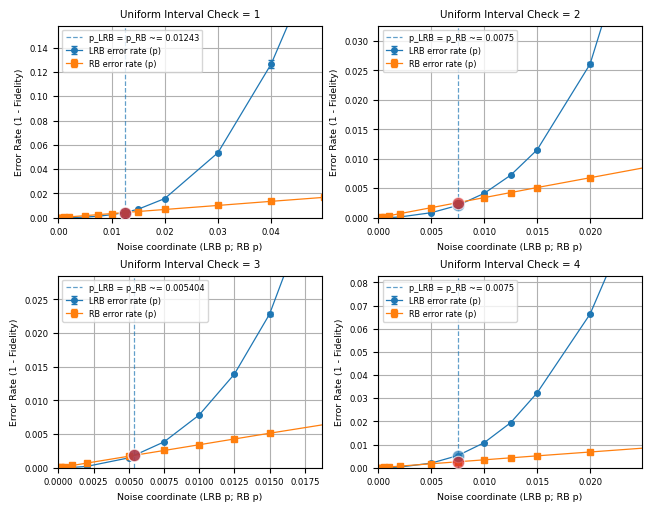

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-09-folded_qubit_prod5b-single-ancilla-si1000-sdim140/results/plots/unif-threshold-error-vs-p-paper-grid.pdf
[THRESHOLD] Uniform Interval Check = 1: p_LRB = p_RB = 0.0124304 +- 0.000152
[THRESHOLD] Uniform Interval Check = 2: p_LRB = p_RB = 0.0075 +- 0.000424
[THRESHOLD] Uniform Interval Check = 3: p_LRB = p_RB = 0.00540437 +- 2.98e-05
[THRESHOLD] Uniform Interval Check = 4: p_LRB = p_RB = 0.0075 +- 0.00141
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-09-folded_qubit_prod5b-single-ancilla-si1000-sdim140/results/plots/unif_thresholds_summary_monotone_trim_zoom_pwindow.csv
[prod5b_qubit_si1000] error-rate uncertainty table


,check_num,lrb_lambda,rb_p,p_raw,p,lrb_error_rate,lrb_error_rate_ci_low,lrb_error_rate_ci_high,rb_error_rate,rb_error_rate_ci_low,rb_error_rate_ci_high,lrb_unc_minus,lrb_unc_plus,rb_unc_minus,rb_unc_plus
0,1,0.0000,0.0000,0.0000,0.0000,0.000000e+00,0.000000e+00,2.500000e-08,0.000000,0.000000,0.000000,0.000000e+00,2.500000e-08,0.000000,0.000000
1,1,0.0001,0.0001,0.0001,0.0001,7.500000e-08,0.000000e+00,2.512500e-07,0.000034,0.000033,0.000035,7.500000e-08,1.762500e-07,0.000001,0.000001
2,1,0.0002,0.0002,0.0002,0.0002,1.071000e-06,8.925000e-07,1.261903e-06,0.000066,0.000064,0.000068,1.785000e-07,1.909031e-07,0.000002,0.000002
3,1,0.0005,0.0005,0.0005,0.0005,4.246419e-06,3.854412e-06,4.651302e-06,0.000168,0.000166,0.000171,3.920062e-07,4.048837e-07,0.000003,0.000003
4,1,0.0010,0.0010,0.0010,0.0010,1.811465e-05,1.742180e-05,1.874961e-05,0.000340,0.000335,0.000343,6.928502e-07,6.349644e-07,0.000004,0.000004
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
325,22,0.0150,0.0150,0.0150,0.0150,9.729960e-02,9.707434e-02,9.752813e-02,0.005123,0.005079,0.005167,2.252640e-04,2.285280e-04,0.000044,0.000043
326,22,0.0200,0.0200,0.0200,0.0200,1.379504e-01,1.374190e-01,1.384401e-01,0.006784,0.006716,0.006844,5.313760e-04,4.897280e-04,0.000069,0.000060
327,22,0.0300,0.0300,0.0300,0.0300,2.183792e-01,2.170489e-01,2.197639e-01,0.010116,0.010027,0.010200,1.330256e-03,1.384720e-03,0.000089,0.000083
328,22,0.0400,0.0400,0.0400,0.0400,2.864520e-01,2.846915e-01,2.884662e-01,0.013486,0.013365,0.013602,1.760528e-03,2.014240e-03,0.000121,0.000116


[prod5b_qubit_si1000] pseudo-threshold uncertainty table


,check_num,threshold_lrb_lambda,threshold_lrb_lambda_std_boot,threshold_lrb_lambda_ci_low,threshold_lrb_lambda_ci_high,threshold_unc_minus,threshold_unc_plus
0,1,0.012430,0.000152,0.012206,0.012500,0.000224,0.000070
1,2,0.007500,0.000424,0.007500,0.008504,0.000000,0.001004
2,3,0.005404,0.000030,0.005375,0.005434,0.000029,0.000030
3,4,0.007500,0.001406,0.003835,0.007500,0.003665,0.000000


=== prod5b_qubit_sd6


[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-27-folded_qubit_prod5b-single-ancilla-sd6-sdim140/results/plots/unif_lrb_vs_rb_table_all_mixed_fits.csv
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-27-folded_qubit_prod5b-single-ancilla-sd6-sdim140/results/plots/unif-1-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-27-folded_qubit_prod5b-single-ancilla-sd6-sdim140/results/plots/unif-2-lrb-vs-rb-table-mixed-fits.csv
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-27-folded_qubit_prod5b-single-ancilla-sd6-sdim140/results/plots/unif-3-lrb-vs-rb-table-mixed-fit

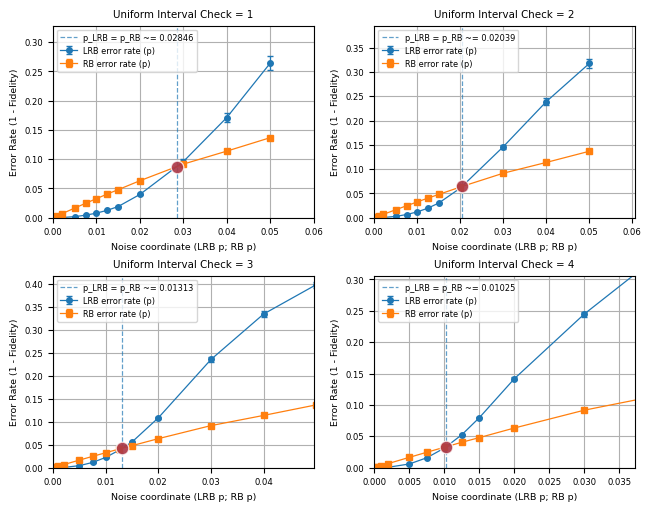

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-27-folded_qubit_prod5b-single-ancilla-sd6-sdim140/results/plots/unif-threshold-error-vs-p-paper-grid.pdf
[THRESHOLD] Uniform Interval Check = 1: p_LRB = p_RB = 0.0284589 +- 0.00109
[THRESHOLD] Uniform Interval Check = 2: p_LRB = p_RB = 0.0203929 +- 0.000302
[THRESHOLD] Uniform Interval Check = 3: p_LRB = p_RB = 0.0131279 +- 0.000145
[THRESHOLD] Uniform Interval Check = 4: p_LRB = p_RB = 0.0102492 +- 9.61e-05
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-27-folded_qubit_prod5b-single-ancilla-sd6-sdim140/results/plots/unif_thresholds_summary_monotone_trim_zoom_pwindow.csv
[prod5b_qubit_sd6] error-rate uncertainty table


,check_num,lrb_lambda,rb_p,p_raw,p,lrb_error_rate,lrb_error_rate_ci_low,lrb_error_rate_ci_high,rb_error_rate,rb_error_rate_ci_low,rb_error_rate_ci_high,lrb_unc_minus,lrb_unc_plus,rb_unc_minus,rb_unc_plus
0,1,0.0000,0.0000,0.0000,0.0000,0.000000e+00,0.000000e+00,2.500000e-08,0.000000,0.000000,0.000000,0.000000e+00,2.500000e-08,0.000000,0.000000
1,1,0.0001,0.0001,0.0001,0.0001,8.120000e-07,6.851250e-07,9.690000e-07,0.000336,0.000332,0.000340,1.268750e-07,1.570000e-07,0.000004,0.000004
2,1,0.0002,0.0002,0.0002,0.0002,3.494887e-06,3.237733e-06,3.745837e-06,0.000667,0.000660,0.000673,2.571544e-07,2.509500e-07,0.000007,0.000006
3,1,0.0005,0.0005,0.0005,0.0005,2.114649e-05,2.052211e-05,2.173375e-05,0.001681,0.001666,0.001695,6.243763e-07,5.872636e-07,0.000014,0.000015
4,1,0.0010,0.0010,0.0010,0.0010,7.907332e-05,7.759854e-05,8.059303e-05,0.003353,0.003326,0.003380,1.474785e-06,1.519709e-06,0.000027,0.000026
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
325,22,0.0150,0.0150,0.0150,0.0150,1.664368e-01,1.653573e-01,1.673048e-01,0.047966,0.047612,0.048319,1.079504e-03,8.680480e-04,0.000354,0.000353
326,22,0.0200,0.0200,0.0200,0.0200,2.153612e-01,2.132844e-01,2.172066e-01,0.063226,0.062722,0.063677,2.076832e-03,1.845424e-03,0.000504,0.000450
327,22,0.0300,0.0300,0.0300,0.0300,2.989064e-01,2.959720e-01,3.016652e-01,0.091633,0.090817,0.092360,2.934416e-03,2.758800e-03,0.000816,0.000728
328,22,0.0400,0.0400,0.0400,0.0400,3.562600e-01,3.521957e-01,3.606634e-01,0.113799,0.112646,0.114939,4.064288e-03,4.403424e-03,0.001153,0.001140


[prod5b_qubit_sd6] pseudo-threshold uncertainty table


,check_num,threshold_lrb_lambda,threshold_lrb_lambda_std_boot,threshold_lrb_lambda_ci_low,threshold_lrb_lambda_ci_high,threshold_unc_minus,threshold_unc_plus
0,1,0.028459,0.001092,0.027342,0.029792,0.001117,0.001333
1,2,0.020393,0.000302,0.020120,0.020680,0.000273,0.000287
2,3,0.013128,0.000145,0.012984,0.013270,0.000144,0.000142
3,4,0.010249,0.000096,0.010161,0.010334,0.000088,0.000085


In [7]:
point_ci_columns = [
    "lrb_error_rate_std_boot",
    "lrb_error_rate_ci_low",
    "lrb_error_rate_ci_high",
    "rb_error_rate_std_boot",
    "rb_error_rate_ci_low",
    "rb_error_rate_ci_high",
]
force_rebuild_uncertainty_table = False


def table_has_point_uncertainty(path: Path) -> bool:
    if not path.exists():
        return False
    columns = pd.read_csv(path, nrows=0).columns
    return all(col in columns for col in point_ci_columns)


table_csvs, summary_csvs, uncertainty_tables, pseudo_threshold_tables = {}, {}, {}, {}
for label, plotter in plotters.items():
    print(f"=== {label}")
    table_csv_path = Path(plotter.out_dir) / "unif_lrb_vs_rb_table_all_mixed_fits.csv"
    if force_rebuild_uncertainty_table or not table_has_point_uncertainty(table_csv_path):
        table_csvs[label] = plotter.build_unif_lrb_vs_rb_table_mixed_fits(
            write_per_check_tables=True,
            check_min=unif_check_min,
            check_max=unif_check_max,
            bootstrap_reps=threshold_config.bootstrap_reps_error,
            bootstrap_ci_level=threshold_config.bootstrap_ci_level,
            bootstrap_use_sem=threshold_config.bootstrap_use_sem,
            bootstrap_seed=threshold_config.bootstrap_seed,
        )
    else:
        table_csvs[label] = str(table_csv_path)
    summary_csvs[label] = plotter.plot_all_unif_threshold_graphs(
        threshold_config=threshold_config,
        table_csv_path=table_csvs[label],
        show=True,
        check_min=unif_check_min,
        check_max=4,
    )
    uncertainty_tables[label] = show_error_rate_uncertainty_table(table_csvs[label], label=label)
    pseudo_threshold_tables[label] = show_pseudo_threshold_uncertainty_table(
        summary_csvs[label],
        label=label,
        check_min=unif_check_min,
        check_max=unif_check_max,
    )

### 7. Pseudo-threshold trend vs interval check

The focused `1..4` pseudo-threshold trend for every run.

[PSEUDO] Uniform Interval Check = 1: p_LRB = p_RB = 0.0124304 +- 0.000152
[PSEUDO] Uniform Interval Check = 2: p_LRB = p_RB = 0.0075 +- 0.000424
[PSEUDO] Uniform Interval Check = 3: p_LRB = p_RB = 0.00540437 +- 2.98e-05
[PSEUDO] Uniform Interval Check = 4: p_LRB = p_RB = 0.0075 +- 0.00141
[FIT] fit disabled by do_fit=False.


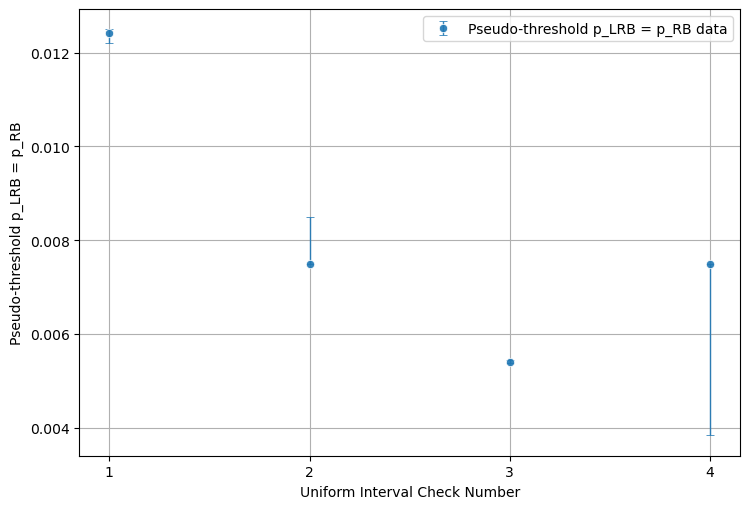

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-09-folded_qubit_prod5b-single-ancilla-si1000-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf
[PSEUDO] Uniform Interval Check = 1: p_LRB = p_RB = 0.0284589 +- 0.00109
[PSEUDO] Uniform Interval Check = 2: p_LRB = p_RB = 0.0203929 +- 0.000302
[PSEUDO] Uniform Interval Check = 3: p_LRB = p_RB = 0.0131279 +- 0.000145
[PSEUDO] Uniform Interval Check = 4: p_LRB = p_RB = 0.0102492 +- 9.61e-05
[FIT] fit disabled by do_fit=False.


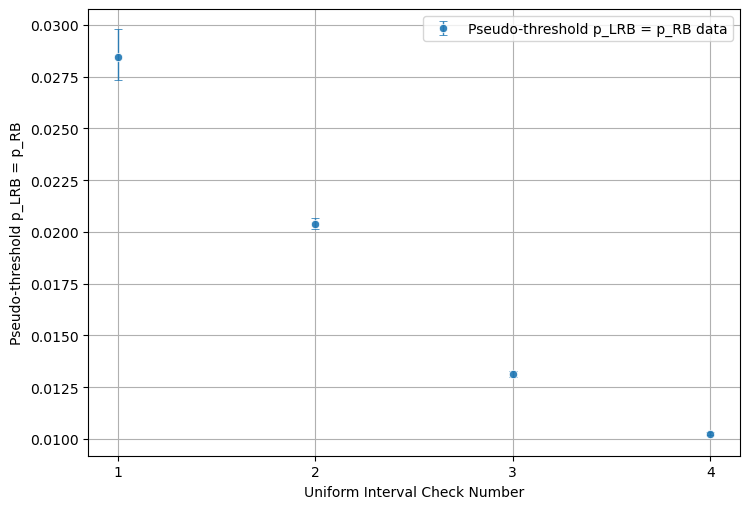

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-27-folded_qubit_prod5b-single-ancilla-sd6-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf


{'prod5b_qubit_si1000': '/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-09-folded_qubit_prod5b-single-ancilla-si1000-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf',
 'prod5b_qubit_sd6': '/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/Run-2026-11-19-23-39-27-folded_qubit_prod5b-single-ancilla-sd6-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf'}

In [8]:
pseudo_pdfs = {}
for label, plotter in plotters.items():
    pseudo_pdfs[label] = plotter.plot_unif_pseudo_thresholds_vs_interval_check(
        check_min=unif_check_min,
        check_max=4,
        do_fit=pseudo_do_fit,
        fit_model=pseudo_fit_model,
        fit_degree=pseudo_fit_degree,
        paper_mode=paper_plot_config.enabled,
        show=True,
    )
pseudo_pdfs

### 8. Comparison with the seven-moment round

Logical error per Clifford with a check after every Clifford (uniform interval 1) versus the two-qudit gate error $p$, for the published one-ancilla runs (seven-moment round) and their paired copies with the five-moment round (same Clifford sequences), against physical RB. The published runs' tables are read as saved. Points without a valid fit are omitted. Merged pseudo-thresholds and the paired comparison come from the scripts named in the reading guide.


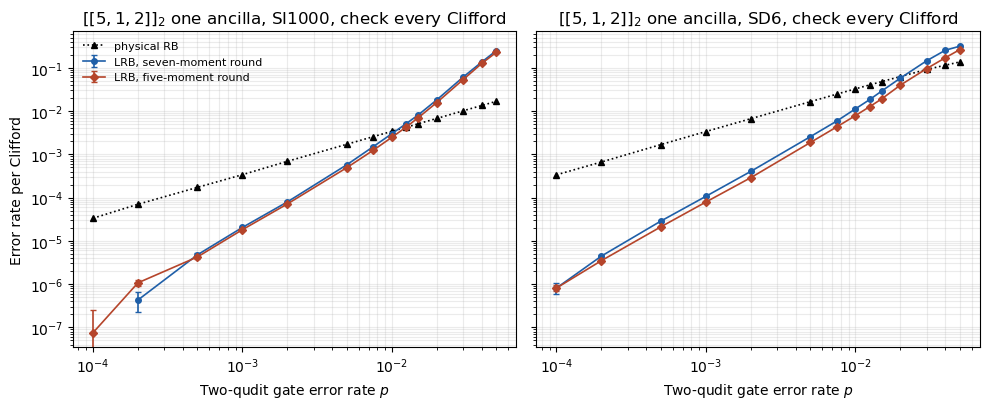

/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/one-ancilla-prod5b/LRB-experiment-data-slurm/comparisons/sdim140-prod5b/lrb-vs-rb-unif-1-qubit-five-vs-seven-moment.pdf


In [9]:
import matplotlib.pyplot as plt
import numpy as np

comparison_dir = RUNS_ROOT / "comparisons" / "sdim140-prod5b"
comparison_dir.mkdir(parents=True, exist_ok=True)
comparison_check = 1
TABLE_NAME = "unif_lrb_vs_rb_table_all_mixed_fits.csv"
CURRENT_RUNS = {
    "si1000": "Run-2026-10-31-10-12-55-folded_qubit-single-ancilla-si1000-sdim140",
    "sd6": "Run-2026-10-31-10-13-03-folded_qubit-single-ancilla-sd6-sdim140",
}
CURRENT, NEW = "seven-moment round", "five-moment round"
tables = {(noise, CURRENT): RUNS_ROOT / run / "results" / "plots" / TABLE_NAME
          for noise, run in CURRENT_RUNS.items()}
for label, table_csv in table_csvs.items():
    tables[(label.split("_")[-1], NEW)] = Path(table_csv)
styles = {
    CURRENT: dict(color="#1f5fa8", marker="o", linestyle="-"),
    NEW: dict(color="#b5452b", marker="D", linestyle="-"),
}
rows = []
fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.2), sharey=True)
for ax, noise in zip(axes, ("si1000", "sd6")):
    for layout, style in styles.items():
        frame = pd.read_csv(tables[(noise, layout)])
        frame = frame[(frame["check_num"] == comparison_check) & (frame["p"] > 0)].sort_values("p")
        lrb = frame[np.isfinite(frame["lrb_error_rate"]) & (frame["lrb_error_rate"] > 0)]
        yerr = np.vstack([
            lrb["lrb_error_rate"] - lrb["lrb_error_rate_ci_low"],
            lrb["lrb_error_rate_ci_high"] - lrb["lrb_error_rate"],
        ]).clip(min=0)
        ax.errorbar(lrb["p"], lrb["lrb_error_rate"], yerr=yerr, markersize=4, capsize=2,
                    linewidth=1.2, label=f"LRB, {layout}", **style)
        rows.append(frame.assign(noise=noise, round=layout))
    frame = pd.read_csv(tables[(noise, CURRENT)])
    frame = frame[(frame["check_num"] == comparison_check) & (frame["p"] > 0)].sort_values("p")
    rb = frame[np.isfinite(frame["rb_error_rate"]) & (frame["rb_error_rate"] > 0)]
    ax.plot(rb["p"], rb["rb_error_rate"], color="black", linestyle=":", marker="^", markersize=4,
            linewidth=1.2, label="physical RB")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(fit_config.p_axis_label)
    ax.set_title(f"$[[5,1,2]]_2$ one ancilla, {noise.upper()}, check every Clifford")
    ax.grid(True, which="both", alpha=0.25)
axes[0].set_ylabel("Error rate per Clifford")
axes[0].legend(fontsize=8, frameon=False)
fig.tight_layout()
comparison_pdf = comparison_dir / f"lrb-vs-rb-unif-{comparison_check}-qubit-five-vs-seven-moment.pdf"
fig.savefig(comparison_pdf)
fig.savefig(comparison_pdf.with_suffix(".png"), dpi=160)
plt.show()
print(comparison_pdf)
comparison_table = pd.concat(rows, ignore_index=True)[
    ["noise", "round", "p", "lrb_error_rate", "lrb_error_rate_ci_low", "lrb_error_rate_ci_high",
     "rb_error_rate", "rb_error_rate_ci_low", "rb_error_rate_ci_high"]
]
comparison_table.to_csv(comparison_dir / f"lrb-vs-rb-unif-{comparison_check}-qubit-five-vs-seven-moment.csv", index=False)


## 9. Reading guide

Per-run PDFs and tables are under each run's `results/plots/`; the round comparison is under `LRB-experiment-data-slurm/comparisons/sdim140-prod5b/`. Pseudo-thresholds with the threshold refinements merged in come from `scripts/merge_highp_threshold_extension.py qubit-prod5b-sd6 qubit-prod5b-si1000` (hand-off `comparisons/pseudo-thresholds-qubit-prod5b-current.md`); the paired p* comparison with the seven-moment round from `scripts/compare_round_variant_thresholds.py --family qubit`. GIF animations are not made for these runs. In every figure the horizontal axis is the two-qudit gate depolarizing probability $p$; SI1000 sets one-qudit gates to $p/10$, measurement flips to $5p$, reset flips and resonator idles to $2p$, and idles to $p/10$, and SD6 sets every operation to $p$.
